# Análise exploratória da base de YouTube Shorts

Base coletada em 13/10/2026 pela YouTube Data API v3 (`python -m creative_predictor.collect.shorts`).
Shorts de canais de moda, beleza e automotivo publicados entre 15/10/2024 e 28/08/2026, mais os
50 Shorts anteriores de cada canal, usados só como histórico.

O alvo do modelo é o desempenho do Short em relação ao próprio canal:
`y = log((curtidas + 1) / (mediana + 1))`, com a mediana das curtidas dos 20 Shorts anteriores
do canal (`creative_predictor.features.target`). `y = 0` é um Short típico do canal; `y = 0,69`
tem o dobro das curtidas da mediana.

Salvo indicação, as análises usam os canais de treino (sem os canais de demonstração) e os Shorts
dentro da janela.

In [1]:
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from creative_predictor import config
from creative_predictor.features.target import add_target


# Spearman = Pearson sobre os postos (sem depender da scipy).
def spearman(a, b):
    return a.rank().corr(b.rank())


pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})

shorts = pd.read_parquet(config.PROCESSED_DIR / "shorts.parquet")
channels = pd.read_parquet(config.PROCESSED_DIR / "channels.parquet")
shorts = add_target(shorts)

# Hora local de publicação: Brasil em São Paulo; canais globais pelo país do canal.
TIMEZONES = {
    "BR": "America/Sao_Paulo",
    "US": "America/New_York",
    "GB": "Europe/London",
    "DE": "Europe/Berlin",
    "FR": "Europe/Paris",
    "IT": "Europe/Rome",
    "ES": "Europe/Madrid",
    "SE": "Europe/Stockholm",
}
country = channels.set_index("channel_id")["country"]
region = channels.set_index("channel_id")["region"]
tz = shorts["channel_id"].map(country).map(TIMEZONES)
tz = tz.where(
    tz.notna(),
    np.where(shorts["channel_id"].map(region) == "br", "America/Sao_Paulo", "UTC"),
)
local = [ts.tz_convert(z) for ts, z in zip(shorts["published_at"], tz)]
shorts["local_hour"] = [t.hour for t in local]
shorts["local_weekday"] = [t.dayofweek for t in local]
shorts["month"] = shorts["published_at"].dt.tz_convert(None).dt.to_period("M")
shorts["quarter"] = shorts["published_at"].dt.tz_convert(None).dt.to_period("Q")

window = shorts[shorts["in_window"] & ~shorts["holdout"]].copy()
with_target = window.dropna(subset=["target"])
print(
    f"{len(shorts):,} Shorts no total; {len(window):,} na janela (canais de treino); "
    f"{len(with_target):,} com alvo; {window['media_sample'].sum():,} na amostra multimodal"
)

34,687 Shorts no total; 30,187 na janela (canais de treino); 30,060 com alvo; 9,554 na amostra multimodal


## 1. Volume e composição

In [2]:
train_channels = channels[~channels["holdout"]]
print(
    pd.crosstab(
        train_channels["sector"],
        [train_channels["region"], train_channels["kind"]],
        margins=True,
        margins_name="total",
    )
)
print()
print(
    window.groupby(["sector", "region"]).agg(
        shorts=("video_id", "size"),
        amostra=("media_sample", "sum"),
        canais=("channel_id", "nunique"),
    )
)

region          br        global       total
kind       criador marca criador marca      
sector                                      
automotivo      16     3       3     6    28
beleza          14     6       2     9    31
moda            17     4       0     7    28
total           47    13       5    22    87

                   shorts  amostra  canais
sector     region                         
automotivo br        6405     2176      19
           global    3418     1029       9
beleza     br        6771     2119      20
           global    3872     1229      11
moda       br        7555     2178      21
           global    2166      823       7


count      87.0
mean      347.0
std       318.0
min        52.0
25%       129.0
50%       263.0
75%       445.0
max      1909.0
dtype: float64


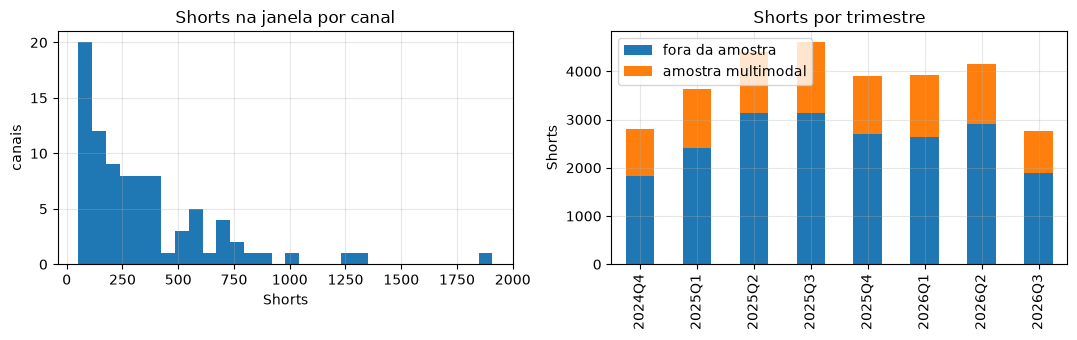

In [3]:
per_channel = window.groupby("channel_id").size()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(per_channel, bins=30)
axes[0].set(title="Shorts na janela por canal", xlabel="Shorts", ylabel="canais")
window.groupby(["quarter", "media_sample"]).size().unstack().plot.bar(
    stacked=True, ax=axes[1]
)
axes[1].set(title="Shorts por trimestre", xlabel="", ylabel="Shorts")
axes[1].legend(["fora da amostra", "amostra multimodal"])
plt.tight_layout()
print(per_channel.describe().round(0))

A amostra multimodal (até 120 Shorts por canal) se distribui de forma parecida entre os trimestres,
enquanto o total de Shorts varia muito entre canais: canais que postam muito ficam com a mesma
cobertura no tempo que os demais. 2024T4 e 2026T3 são trimestres incompletos (janela começa em 15/10
e termina em 28/08).

## 2. Qualidade dos dados

In [4]:
cols = [
    "title",
    "description",
    "tags",
    "category_id",
    "default_audio_language",
    "duration_s",
    "views",
    "likes",
    "comments",
    "has_paid_placement",
]
empty = lambda s: s.isna() | s.map(lambda v: hasattr(v, "__len__") and len(v) == 0)
quality = pd.DataFrame(
    {"vazios_%": [100 * empty(window[c]).mean() for c in cols]}, index=cols
).round(1)
print(quality)
print()
print("Duplicatas de video_id:", shorts["video_id"].duplicated().sum())
print("Shorts com mais de 180 s:", (window["duration_s"] > 180).sum())
names = channels.set_index("channel_id")["name"]
print(
    "Curtidas ocultas por canal:",
    window.loc[window["likes"].isna(), "channel_id"]
    .map(names)
    .value_counts()
    .head(5)
    .to_dict(),
)
print("Idade mínima na coleta (dias):", window["age_days"].min())
print()
print("Idioma do áudio declarado (top 8):")
print(window["default_audio_language"].value_counts(dropna=False).head(8))

                        vazios_%
title                        0.0
description                 48.9
tags                        79.0
category_id                  0.0
default_audio_language      18.6
duration_s                   0.0
views                        0.0
likes                        0.4
comments                     0.1
has_paid_placement           0.0

Duplicatas de video_id: 0
Shorts com mais de 180 s: 88
Curtidas ocultas por canal: {'AoRaboni': 36, 'Carros do Xenão': 29, 'Fran Barreto': 15, 'Motor1 Brasil': 7, 'Kim da Moda': 6}
Idade mínima na coleta (dias): 46

Idioma do áudio declarado (top 8):
default_audio_language
pt-BR    8849
en       7053
pt       5925
NaN      5617
sa       1272
en-US    1184
en-GB     163
pt-PT      66
Name: count, dtype: int64


- Curtidas ocultas são raras fora dos 4 canais retirados da base (106 Shorts, concentrados em
  poucos canais automotivos e de moda); esses Shorts ficam sem alvo, mas não distorcem o histórico.
- O idioma do áudio declarado pelo canal não é confiável: o código `sa` (sânscrito) aparece em mais
  de mil Shorts e ~20% vêm sem idioma. O idioma vai vir da transcrição (Whisper), não da API.
- Tags e descrição vazias são comuns; o texto principal do Short é o título.

## 3. Curtidas, views e a escolha do alvo

Shorts com curtidas < 0,3% das views (cara de anúncio):
kind
criador    0.002
marca       0.02
Name: anuncio, dtype: Float64


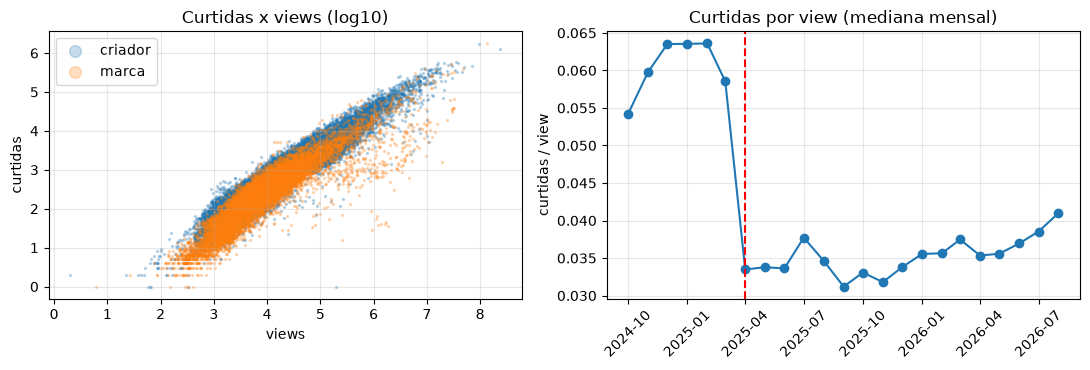

In [5]:
w = window[window["likes"].notna() & (window["views"] > 0)].copy()
w["like_rate"] = w["likes"] / w["views"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for kind, g in w.groupby("kind"):
    axes[0].scatter(
        np.log10(g["views"] + 1), np.log10(g["likes"] + 1), s=2, alpha=0.25, label=kind
    )
axes[0].set(title="Curtidas x views (log10)", xlabel="views", ylabel="curtidas")
axes[0].legend(markerscale=6)
monthly = w.groupby("month")["like_rate"].median()
axes[1].plot(monthly.index.to_timestamp(), monthly.values, marker="o")
axes[1].axvline(pd.Timestamp("2025-03-31"), color="red", linestyle="--")
axes[1].set(title="Curtidas por view (mediana mensal)", ylabel="curtidas / view")
axes[1].tick_params(axis="x", labelrotation=45)
plt.tight_layout()
print("Shorts com curtidas < 0,3% das views (cara de anúncio):")
print(
    w.assign(anuncio=w["like_rate"] < 0.003).groupby("kind")["anuncio"].mean().round(3)
)

- A razão curtidas/view cai de forma abrupta em abril de 2025 (linha vermelha): em 31/03/2025 o
  YouTube passou a contar como view cada vez que um Short começa a tocar ou repete. Views antes e
  depois dessa data não são comparáveis; curtidas não mudaram de definição.
- Canais de marca têm uma nuvem de Shorts com muitas views e poucas curtidas (Shorts impulsionados
  como anúncio). As views desses Shorts medem a verba de mídia, não a reação ao conteúdo.
- Os dois pontos justificam curtidas como alvo, como o brief recomenda.

## 4. O alvo relativo ao canal

count    30060.000
mean         0.090
std          0.999
min         -9.483
25%         -0.464
50%         -0.017
75%          0.492
max          8.114
Name: target, dtype: float64

Quantis: {0.05: -1.25, 0.25: -0.46, 0.5: -0.02, 0.75: 0.49, 0.95: 1.86, 0.99: 3.48}
Em múltiplos da mediana do canal: {0.25: 0.63, 0.75: 1.64, 0.95: 6.4}

          mean    std  count
kind                        
criador  0.077  0.932  18872
marca    0.113  1.101  11188
                 mean    std  count
low_engagement                     
False           0.094  0.983  29210
True           -0.034  1.435    850


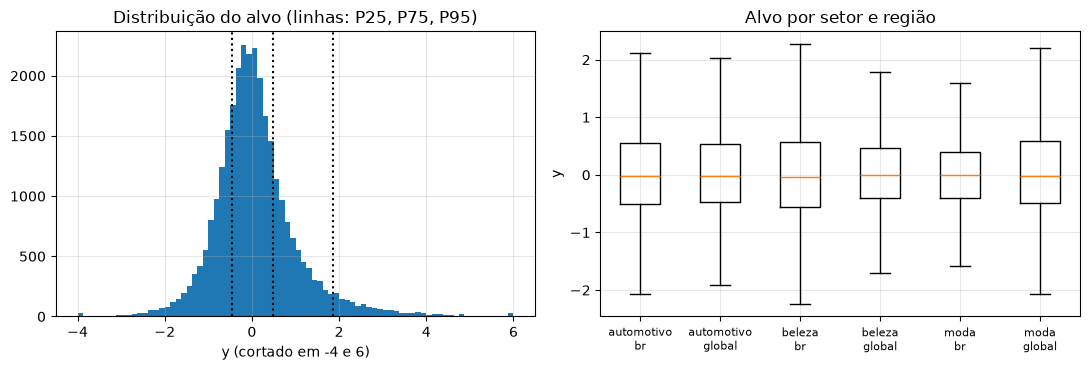

In [6]:
t = with_target
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(t["target"].clip(-4, 6), bins=80)
for q in (0.25, 0.75, 0.95):
    axes[0].axvline(t["target"].quantile(q), color="black", linestyle=":")
axes[0].set(
    title="Distribuição do alvo (linhas: P25, P75, P95)", xlabel="y (cortado em -4 e 6)"
)
groups = [g["target"].to_numpy() for _, g in t.groupby(["sector", "region"])]
labels = [f"{s}\n{r}" for s, r in t.groupby(["sector", "region"]).groups]
axes[1].boxplot(groups, tick_labels=labels, showfliers=False)
axes[1].set(title="Alvo por setor e região", ylabel="y")
axes[1].tick_params(axis="x", labelsize=8)
plt.tight_layout()
print(t["target"].describe().round(3))
print()
print(
    "Quantis:",
    t["target"].quantile([0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(2).to_dict(),
)
print(
    "Em múltiplos da mediana do canal:",
    np.exp(t["target"].quantile([0.25, 0.75, 0.95])).round(2).to_dict(),
)
print()
print(t.groupby("kind")["target"].agg(["mean", "std", "count"]).round(3))
low = channels.set_index("channel_id")["low_engagement"]
print(
    t.groupby(t["channel_id"].map(low))["target"]
    .agg(["mean", "std", "count"])
    .rename_axis("low_engagement")
    .round(3)
)

- O alvo é centrado perto de zero (mediana ≈ 0), com cauda à direita: 5% dos Shorts passam de
  6× a mediana do canal, e só 5% ficam abaixo de ~0,3× dela.
- Proposta de faixas (alvo secundário), pelos quantis do treino: **abaixo** (< P25, ~0,6× a
  mediana), **na média** (P25 a P75), **acima** (P75 a P95, até ~6×) e **viral** (> P95). Os
  limites finais saem do conjunto de treino do split temporal.
- Canais de marca têm alvo mais disperso que criadores (mídia paga e campanhas pontuais), e os
  canais marcados com pouco engajamento (`low_engagement`) são os mais dispersos de todos (dp ≈ 1,4):
  com poucas curtidas por Short, a razão contra a mediana oscila mais. Os dois grupos entram como
  estratos na análise de erros e no sinal de baixa confiança.

## 5. Idade do vídeo e tendência dos canais

             mean  count
age_days                
(30, 60]    0.048    750
(60, 120]   0.041   2781
(120, 240]  0.073   5472
(240, 480]  0.075  10841
(480, 800]  0.132  10216


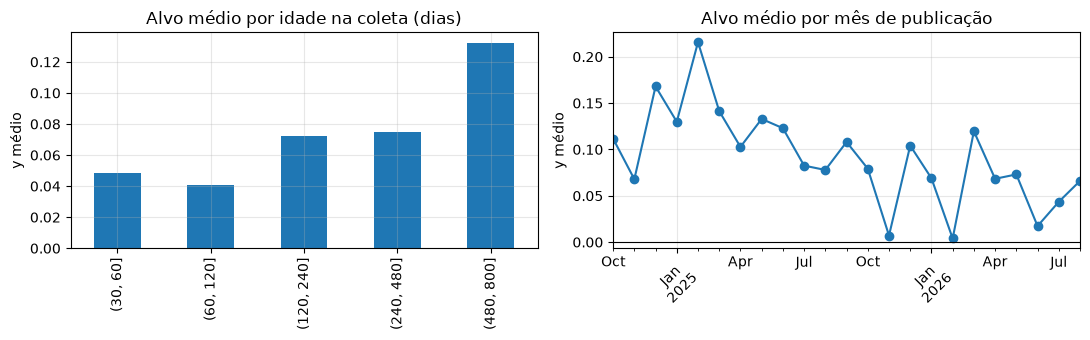

In [7]:
t = with_target
age_bins = pd.cut(t["age_days"], [30, 60, 120, 240, 480, 800])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
t.groupby(age_bins, observed=True)["target"].mean().plot.bar(ax=axes[0])
axes[0].set(title="Alvo médio por idade na coleta (dias)", xlabel="", ylabel="y médio")
t.groupby("month")["target"].mean().plot(ax=axes[1], marker="o")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(title="Alvo médio por mês de publicação", xlabel="", ylabel="y médio")
axes[1].tick_params(axis="x", labelrotation=45)
plt.tight_layout()
print(t.groupby(age_bins, observed=True)["target"].agg(["mean", "count"]).round(3))

O alvo médio é positivo (≈ +0,09) e maior nos vídeos mais antigos. Duas causas se somam: canais em
crescimento (cada Short tende a superar a mediana dos anteriores) e o tempo extra que vídeos antigos
tiveram para acumular curtidas. No split temporal o teste fica com os vídeos mais novos, então a
idade na coleta será guardada como variável de controle e testada na modelagem; ela nunca é usada
como informação do criativo, porque não existe antes da publicação.

## 6. Inércia do canal

In [8]:
t = with_target.sort_values(["channel_id", "published_at"]).copy()
g = t.groupby("channel_id")["target"]
t["prev_1"] = g.shift(1)
t["prev_mean_5"] = g.transform(lambda s: s.shift(1).rolling(5, min_periods=3).mean())
print(t[["target", "prev_1", "prev_mean_5"]].corr(method="spearman").round(3))

             target  prev_1  prev_mean_5
target        1.000   0.138        0.169
prev_1        0.138   1.000        0.490
prev_mean_5   0.169   0.490        1.000


O desempenho relativo do post anterior explica pouco do próximo (Spearman de 0,14 com o post
anterior e 0,17 com a média dos 5 anteriores): depois de descontada a mediana do canal, sobra pouca
inércia. É um sinal útil como feature de histórico, mas
a maior parte da variação está no próprio Short, que é o que o modelo precisa capturar.

## 7. Formato: duração

             mean  count
duration_s              
(0, 15]     0.039   5196
(15, 30]    0.010   6638
(30, 45]    0.047   4531
(45, 60]    0.100   4365
(60, 90]    0.134   5801
(90, 180]   0.290   3441


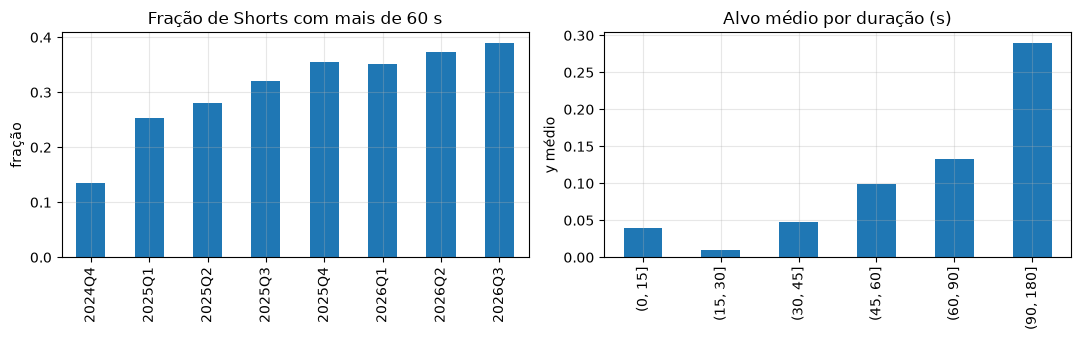

In [9]:
t = with_target
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
window.assign(longo=window["duration_s"] > 60).groupby("quarter")[
    "longo"
].mean().plot.bar(ax=axes[0])
axes[0].set(title="Fração de Shorts com mais de 60 s", xlabel="", ylabel="fração")
dur_bins = pd.cut(t["duration_s"], [0, 15, 30, 45, 60, 90, 180])
t.groupby(dur_bins, observed=True)["target"].mean().plot.bar(ax=axes[1])
axes[1].set(title="Alvo médio por duração (s)", xlabel="", ylabel="y médio")
plt.tight_layout()
print(t.groupby(dur_bins, observed=True)["target"].agg(["mean", "count"]).round(3))

Desde que o YouTube aceitou Shorts de até 3 minutos (15/10/2024, início da janela), a fração de
Shorts com mais de 60 s subiu de forma contínua. A duração é a característica simples com o sinal
mais claro: Shorts de 90 a 180 s têm alvo médio de +0,29, contra +0,01 a +0,05 dos Shorts de até
45 s. O efeito não vem da idade, porque os Shorts longos são os mais recentes, justamente os de alvo
médio menor. É uma feature de formato disponível antes da publicação.

## 8. Horário e dia da semana (hora local do canal)

local_hour      0       1       2      3       4      5       6       7       8        9        10       11      12      13       14       15       16  \
mean          0.11    0.23    0.07   0.21    0.47   0.06    0.07    0.11    0.11     0.01     0.07     0.17     0.1     0.1     0.09     0.08     0.05   
count       184.00  103.00  132.00  69.00  222.00  90.00  116.00  192.00  466.00  1075.00  1284.00  1887.00  3384.0  2111.0  2100.00  2089.00  2604.00   

local_hour       17      18      19       20       21     22      23  
mean           0.09     0.1     0.1     0.06     0.03    0.1    0.08  
count       2509.00  2811.0  2439.0  2386.00  1017.00  503.0  287.00  


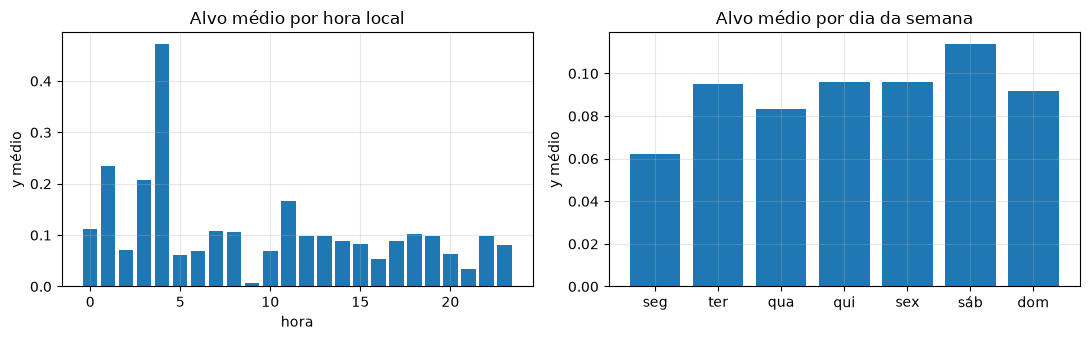

In [10]:
t = with_target
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
by_hour = t.groupby("local_hour")["target"].agg(["mean", "count"])
axes[0].bar(by_hour.index, by_hour["mean"])
axes[0].set(title="Alvo médio por hora local", xlabel="hora", ylabel="y médio")
by_day = t.groupby("local_weekday")["target"].agg(["mean", "count"])
axes[1].bar(["seg", "ter", "qua", "qui", "sex", "sáb", "dom"], by_day["mean"])
axes[1].set(title="Alvo médio por dia da semana", ylabel="y médio")
plt.tight_layout()
print(by_hour.T.round(2))

O horário tem efeito pequeno no alvo médio (as horas da madrugada têm poucos Shorts e médias
instáveis). O horário também varia bastante dentro de cada canal: no canal típico do Brasil, só 42%
dos Shorts saem na hora mais comum do canal (±1 h). Horário e dia da semana entram como features,
mas não se espera muito deles. Os canais globais sem país declarado usam UTC (limitação registrada).

## 9. Texto: título, hashtags e descrição

In [11]:
emoji = re.compile("[\U0001f300-\U0001faff\u2600-\u27bf]")
t = with_target.copy()
title = t["title"].fillna("")
t["title_chars"] = title.str.len()
t["title_words"] = title.str.split().str.len()
t["title_hashtags"] = title.str.count(r"#\w+")
t["title_emojis"] = title.map(lambda s: len(emoji.findall(s)))
t["title_question"] = title.str.contains(r"\?").astype(int)
t["title_upper_ratio"] = title.map(
    lambda s: sum(ch.isupper() for ch in s) / max(1, sum(ch.isalpha() for ch in s))
)
t["desc_chars"] = t["description"].fillna("").str.len()
t["n_tags"] = t["tags"].map(len)
feats = [
    "title_chars",
    "title_words",
    "title_hashtags",
    "title_emojis",
    "title_question",
    "title_upper_ratio",
    "desc_chars",
    "n_tags",
    "duration_s",
    "local_hour",
]
global_corr = t[feats + ["target"]].corr(method="spearman")["target"].drop("target")
# Canais em que a feature é constante geram correlação indefinida (NaN), ignorada na mediana.
warnings.filterwarnings("ignore", "invalid value encountered", RuntimeWarning)


def intra_channel(feature):
    per_channel = t.groupby("channel_id")[[feature, "target"]].apply(
        lambda g: spearman(g[feature], g["target"])
    )
    return per_channel.median()


within = {f: intra_channel(f) for f in feats}
print(
    pd.DataFrame(
        {
            "spearman_global": global_corr,
            "spearman_mediano_intra_canal": pd.Series(within),
        }
    ).round(3)
)

                   spearman_global  spearman_mediano_intra_canal
title_chars                  0.014                         0.006
title_words                  0.012                         0.020
title_hashtags               0.023                         0.026
title_emojis                -0.003                        -0.014
title_question               0.005                        -0.016
title_upper_ratio            0.003                         0.020
desc_chars                  -0.000                         0.011
n_tags                      -0.003                         0.018
duration_s                   0.101                         0.082
local_hour                   0.001                        -0.008


Nenhuma característica simples do texto tem correlação relevante com o alvo, nem no global nem
dentro de cada canal (todas abaixo de 0,03 em módulo); entre as contagens, só a duração se destaca
(0,10). É o esperado: o brief cita Spearman de 0,55 a 0,85 só com o modelo completo, e
nele as features de canal dominam. O sinal de texto tende a vir do conteúdo (embeddings do título e
da transcrição) e não de contagens.

## 10. Tamanho do canal

Spearman inscritos x mediana de curtidas: 0.536
Spearman da mediana dos 20 anteriores x curtidas do Short: 0.862


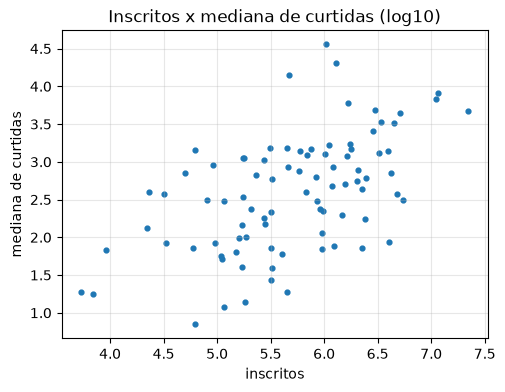

In [12]:
ch = channels[~channels["holdout"]].set_index("channel_id")
med = window.groupby("channel_id")["likes"].median()
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.scatter(np.log10(ch["subscribers"]), np.log10(med.reindex(ch.index) + 1), s=12)
ax.set(
    title="Inscritos x mediana de curtidas (log10)",
    xlabel="inscritos",
    ylabel="mediana de curtidas",
)
print(
    "Spearman inscritos x mediana de curtidas:",
    round(spearman(ch["subscribers"], med.reindex(ch.index)), 3),
)
t = with_target
print(
    "Spearman da mediana dos 20 anteriores x curtidas do Short:",
    round(spearman(t["history_median_likes"], t["likes"].astype(float)), 3),
)

O histórico recente do canal prevê muito bem o volume absoluto de curtidas (Spearman 0,86, contra
0,54 dos inscritos),
bem mais que os inscritos. Isso tem duas consequências: a baseline do canal é forte em valor
absoluto, e o ganho do modelo precisa ser medido no alvo relativo (o que o conteúdo acrescenta ao
canal). Os inscritos são os da data da coleta, não os da publicação, então entram só na baseline de
regressão do brief, com essa ressalva.

## 11. Splits

In [13]:
TRAIN_END, VALID_END = (
    pd.Timestamp("2026-03-01", tz="UTC"),
    pd.Timestamp("2026-06-01", tz="UTC"),
)
t = with_target
split = np.select(
    [t["published_at"] < TRAIN_END, t["published_at"] < VALID_END],
    ["treino", "validação"],
    "teste",
)
summary = (
    t.assign(split=split)
    .groupby(["split", "region"])
    .agg(
        shorts=("video_id", "size"),
        amostra=("media_sample", "sum"),
        canais=("channel_id", "nunique"),
    )
)
print(summary)
test_br = t[(split == "teste") & (t["region"] == "br") & t["media_sample"]]
print()
print(
    "Canais BR com >= 10 Shorts da amostra no teste:",
    (test_br.groupby("channel_id").size() >= 10).sum(),
    "de",
    t.loc[t["region"] == "br", "channel_id"].nunique(),
)

                  shorts  amostra  canais
split     region                         
teste     br        2821      903      58
          global    1330      378      25
treino    br       15026     4615      60
          global    6640     2317      27
validação br        2777      952      56
          global    1466      368      24

Canais BR com >= 10 Shorts da amostra no teste: 50 de 60


Proposta de split temporal: treino até fev/2026, validação de mar a mai/2026 e teste de jun a
ago/2026, com o teste restrito aos canais do Brasil (os canais globais entram só no treino). O
split por canal (canais nunca vistos) é feito por grupos de canais, com os 13 canais de
demonstração como teste extra de canais novos.

## 12. Resumo

1. Base: 87 canais de treino (60 do Brasil) e 13 de demonstração; 30.187 Shorts na janela, 30.060
   com alvo; amostra multimodal de 9.554 Shorts distribuídos de forma uniforme no tempo.
2. Curtidas são o alvo certo: views mudaram de definição em 31/03/2025 e incluem mídia paga em
   canais de marca.
3. O alvo relativo é centrado em zero, com cauda longa à direita; faixas propostas por P25/P75/P95.
4. O alvo médio cresce com a idade do vídeo; a idade na coleta será controlada na modelagem.
5. O histórico do canal prevê bem o volume absoluto, mas explica pouco do desempenho relativo do
   próximo Short; o espaço para o modelo está no conteúdo.
6. Características simples do texto têm sinal fraco; a duração é a exceção (Shorts mais longos
   rendem mais em relação ao canal). Embeddings e atributos multimodais são o próximo passo.
7. O idioma declarado pelo canal não é confiável; o idioma vem da transcrição.